In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)
print("TensorFlow executing eagerly:", tf.executing_eagerly())

TensorFlow version: 2.21.0
TensorFlow executing eagerly: True


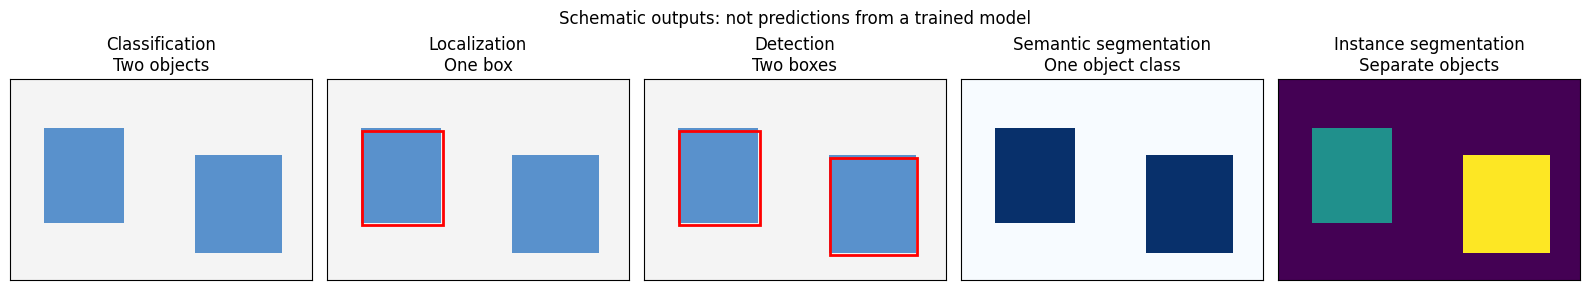

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

h, w = 60, 90
scene = np.ones((h, w, 3), dtype=float) * 0.96
scene[15:43, 10:34] = [0.35, 0.57, 0.80]
scene[23:52, 55:81] = [0.35, 0.57, 0.80]
mask_semantic = np.zeros((h, w), dtype=int)
mask_semantic[15:43, 10:34] = 1
mask_semantic[23:52, 55:81] = 1
mask_instance = np.zeros((h, w), dtype=int)
mask_instance[15:43, 10:34] = 1
mask_instance[23:52, 55:81] = 2

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].imshow(scene)
axes[0].set_title("Classification\nTwo objects")
axes[1].imshow(scene)
axes[1].add_patch(Rectangle((10, 15), 24, 28, fill=False,
                            edgecolor="red", linewidth=2))
axes[1].set_title("Localization\nOne box")
axes[2].imshow(scene)
for x, y, bw, bh in [(10, 15, 24, 28), (55, 23, 26, 29)]:
    axes[2].add_patch(Rectangle((x, y), bw, bh, fill=False,
                                edgecolor="red", linewidth=2))
axes[2].set_title("Detection\nTwo boxes")
axes[3].imshow(mask_semantic, cmap="Blues", vmin=0, vmax=1)
axes[3].set_title("Semantic segmentation\nOne object class")
axes[4].imshow(mask_instance, cmap="viridis", vmin=0, vmax=2)
axes[4].set_title("Instance segmentation\nSeparate objects")
fig.suptitle("Schematic outputs: not predictions from a trained model")
plt.tight_layout()
plt.show()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


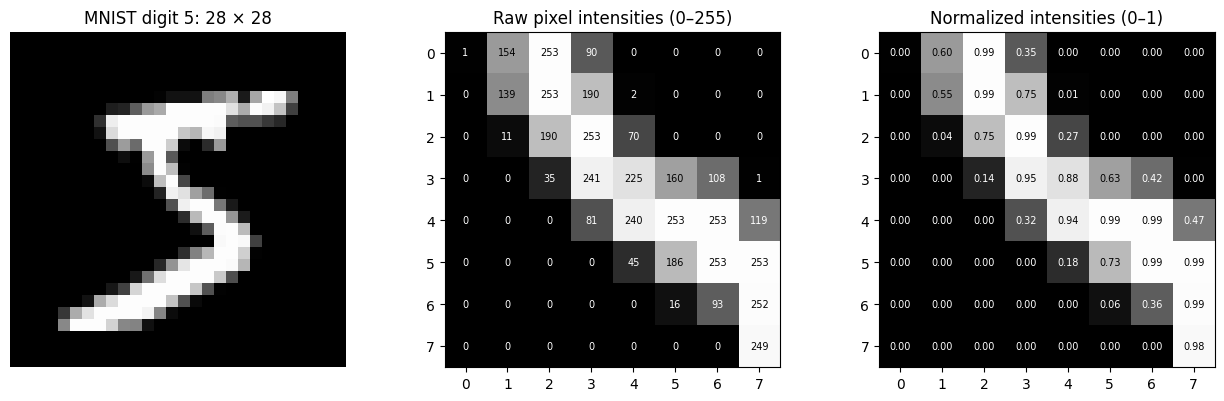

Image shape: (28, 28)
Raw pixel type: uint8
Example pixel before/after scaling: 1 0.003921568859368563


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_digits, y_digits), _ = keras.datasets.mnist.load_data()
index = 0
img = x_digits[index]
patch = img[10:18, 10:18]
normalized = patch.astype("float32") / 255.0

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"MNIST digit {int(y_digits[index])}: 28 × 28")
axes[0].axis("off")

for ax, values, title, formatter in [
    (axes[1], patch, "Raw pixel intensities (0–255)", lambda v: str(int(v))),
    (axes[2], normalized, "Normalized intensities (0–1)",
     lambda v: f"{float(v):.2f}"),
]:
    ax.imshow(values, cmap="gray", vmin=0,
              vmax=255 if ax is axes[1] else 1)
    ax.set_title(title)
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    for r in range(8):
        for c in range(8):
            v = float(values[r, c])
            threshold = 130 if ax is axes[1] else 0.51
            ax.text(c, r, formatter(v), ha="center", va="center",
                    fontsize=7, color="black" if v > threshold else "white")
plt.tight_layout()
plt.show()

print("Image shape:", img.shape)
print("Raw pixel type:", img.dtype)
print("Example pixel before/after scaling:", int(patch[0, 0]),
      float(normalized[0, 0]))

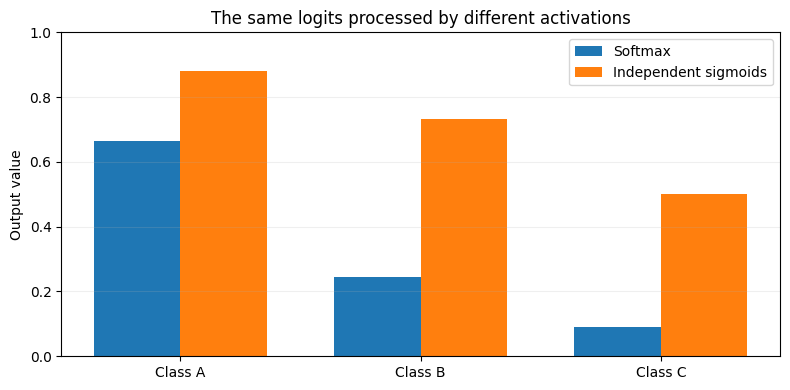

Sparse label: 0
One-hot label: [1. 0. 0.]
Softmax sum: 1.0
Sigmoid sum: 2.1118557
Sparse and one-hot losses: 0.40760598 0.40760598


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

logits = np.array([2.0, 1.0, 0.0], dtype="float32")
softmax = keras.activations.softmax(logits).numpy()
sigmoid = keras.activations.sigmoid(logits).numpy()

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3)
ax.bar(x - 0.18, softmax, width=0.36, label="Softmax")
ax.bar(x + 0.18, sigmoid, width=0.36, label="Independent sigmoids")
ax.set_xticks(x, ["Class A", "Class B", "Class C"])
ax.set_ylim(0, 1)
ax.set_ylabel("Output value")
ax.set_title("The same logits processed by different activations")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

correct_class = 0
one_hot = np.eye(len(logits), dtype="float32")[correct_class]
loss_sparse = -np.log(softmax[correct_class])
loss_one_hot = -np.sum(one_hot * np.log(softmax))
print("Sparse label:", correct_class)
print("One-hot label:", one_hot)
print("Softmax sum:", softmax.sum())
print("Sigmoid sum:", sigmoid.sum())
print("Sparse and one-hot losses:", loss_sparse, loss_one_hot)

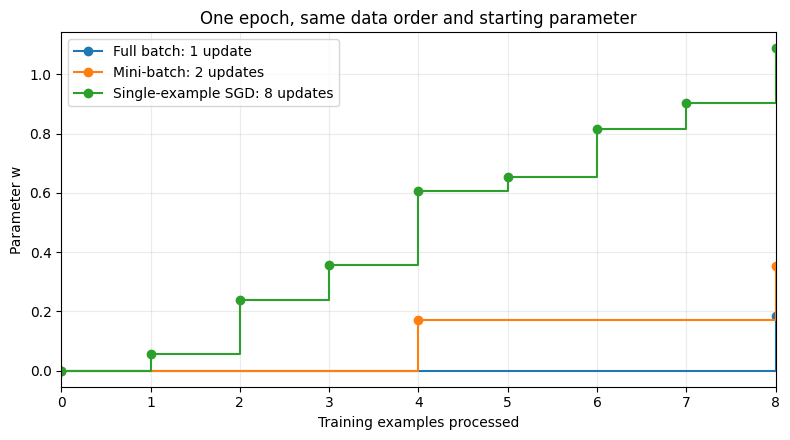

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Toy model: prediction = w*x. Loss = mean(0.5*(w*x - y)**2).
x = np.array([0.5, 1.0, 0.8, 1.2, 0.6, 1.1, 0.9, 1.3], dtype=float)
y = 2.0 * x + np.array([0.1, -0.1, 0.05, 0.1, -0.05, 0.0, -0.1, 0.0])
learning_rate = 0.1

def run_one_epoch(batch_size):
    w = 0.0
    processed = [0]
    weights = [w]
    for start in range(0, len(x), batch_size):
        xb = x[start:start + batch_size]
        yb = y[start:start + batch_size]
        # Forward, loss derivative, and negative-gradient parameter update.
        predictions = w * xb
        gradient = np.mean((predictions - yb) * xb)
        w = w - learning_rate * gradient
        processed.append(start + len(xb))
        weights.append(w)
    return processed, weights

fig, ax = plt.subplots(figsize=(8, 4.5))
for size, label in [(8, "Full batch: 1 update"),
                    (4, "Mini-batch: 2 updates"),
                    (1, "Single-example SGD: 8 updates")]:
    seen, weights = run_one_epoch(size)
    ax.step(seen, weights, where="post", marker="o", label=label)
ax.set(xlabel="Training examples processed", ylabel="Parameter w",
       title="One epoch, same data order and starting parameter")
ax.set_xlim(0, 8)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

Model: "MNIST_Grayscale"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Image (InputLayer)              │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Probabilities (Dense)           │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

MNIST_Grayscale trainable parameters: 269322


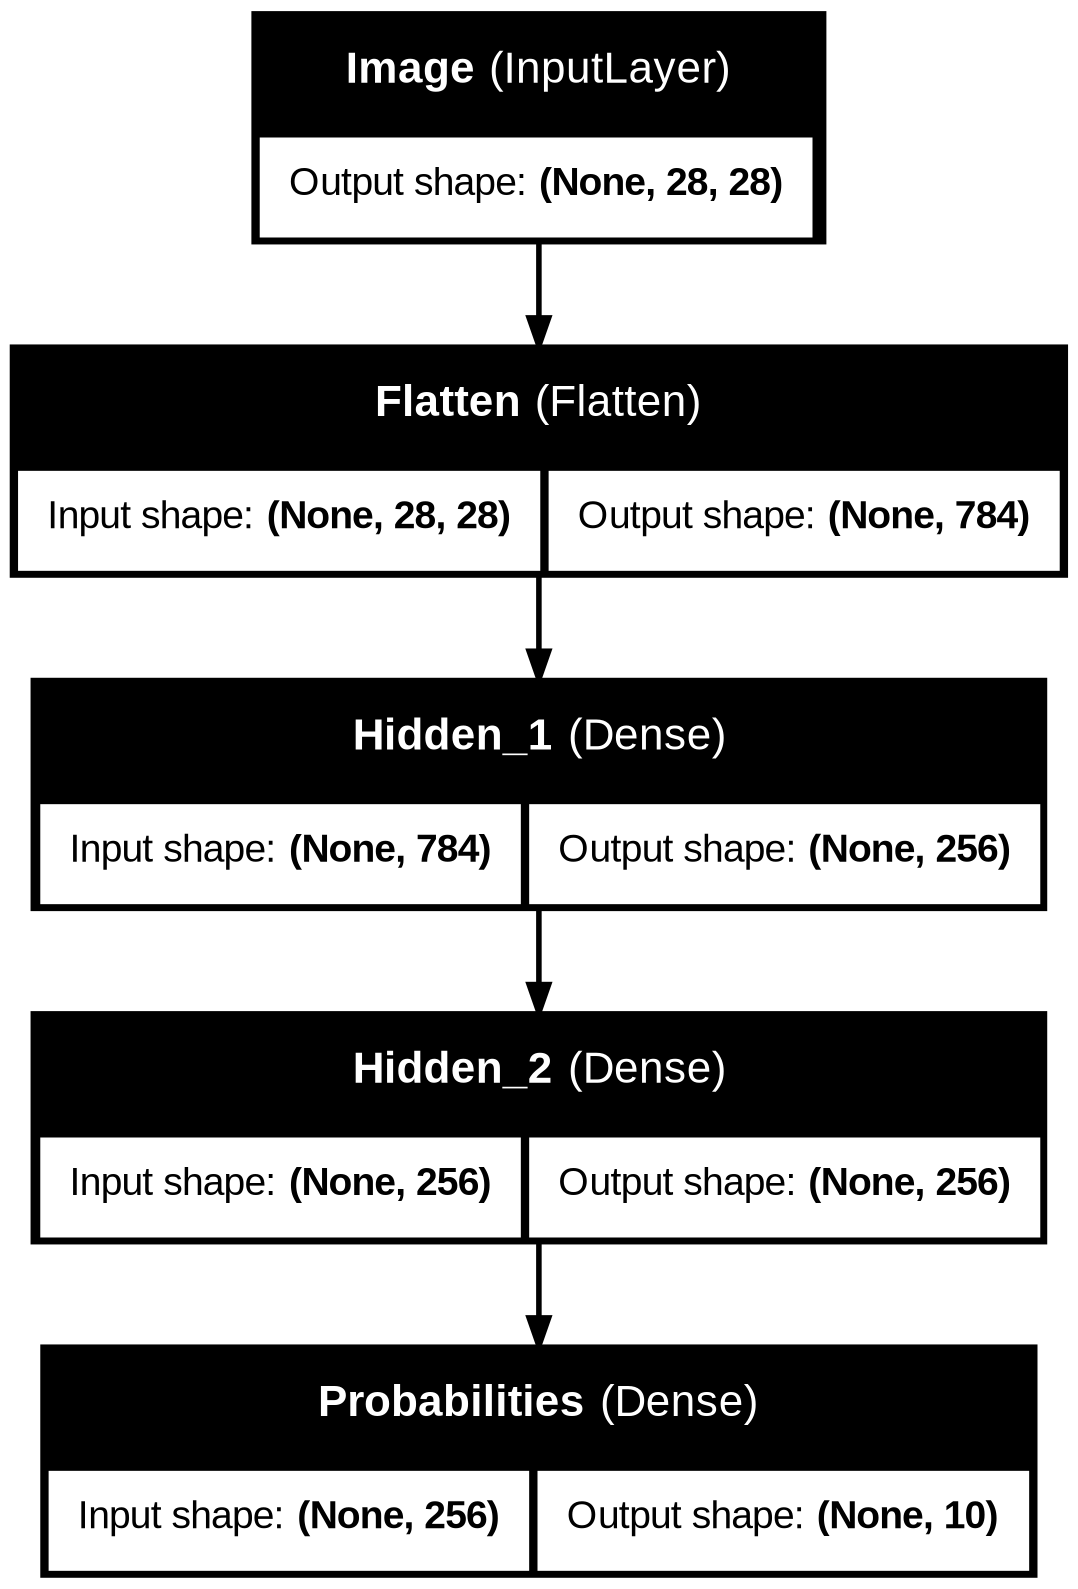

Model: "CIFAR10_RGB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_1 (Dense)                │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Probabilities (Dense)           │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,050 (3.26 MB)

 Trainable params: 855,050 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

CIFAR10_RGB trainable parameters: 855050


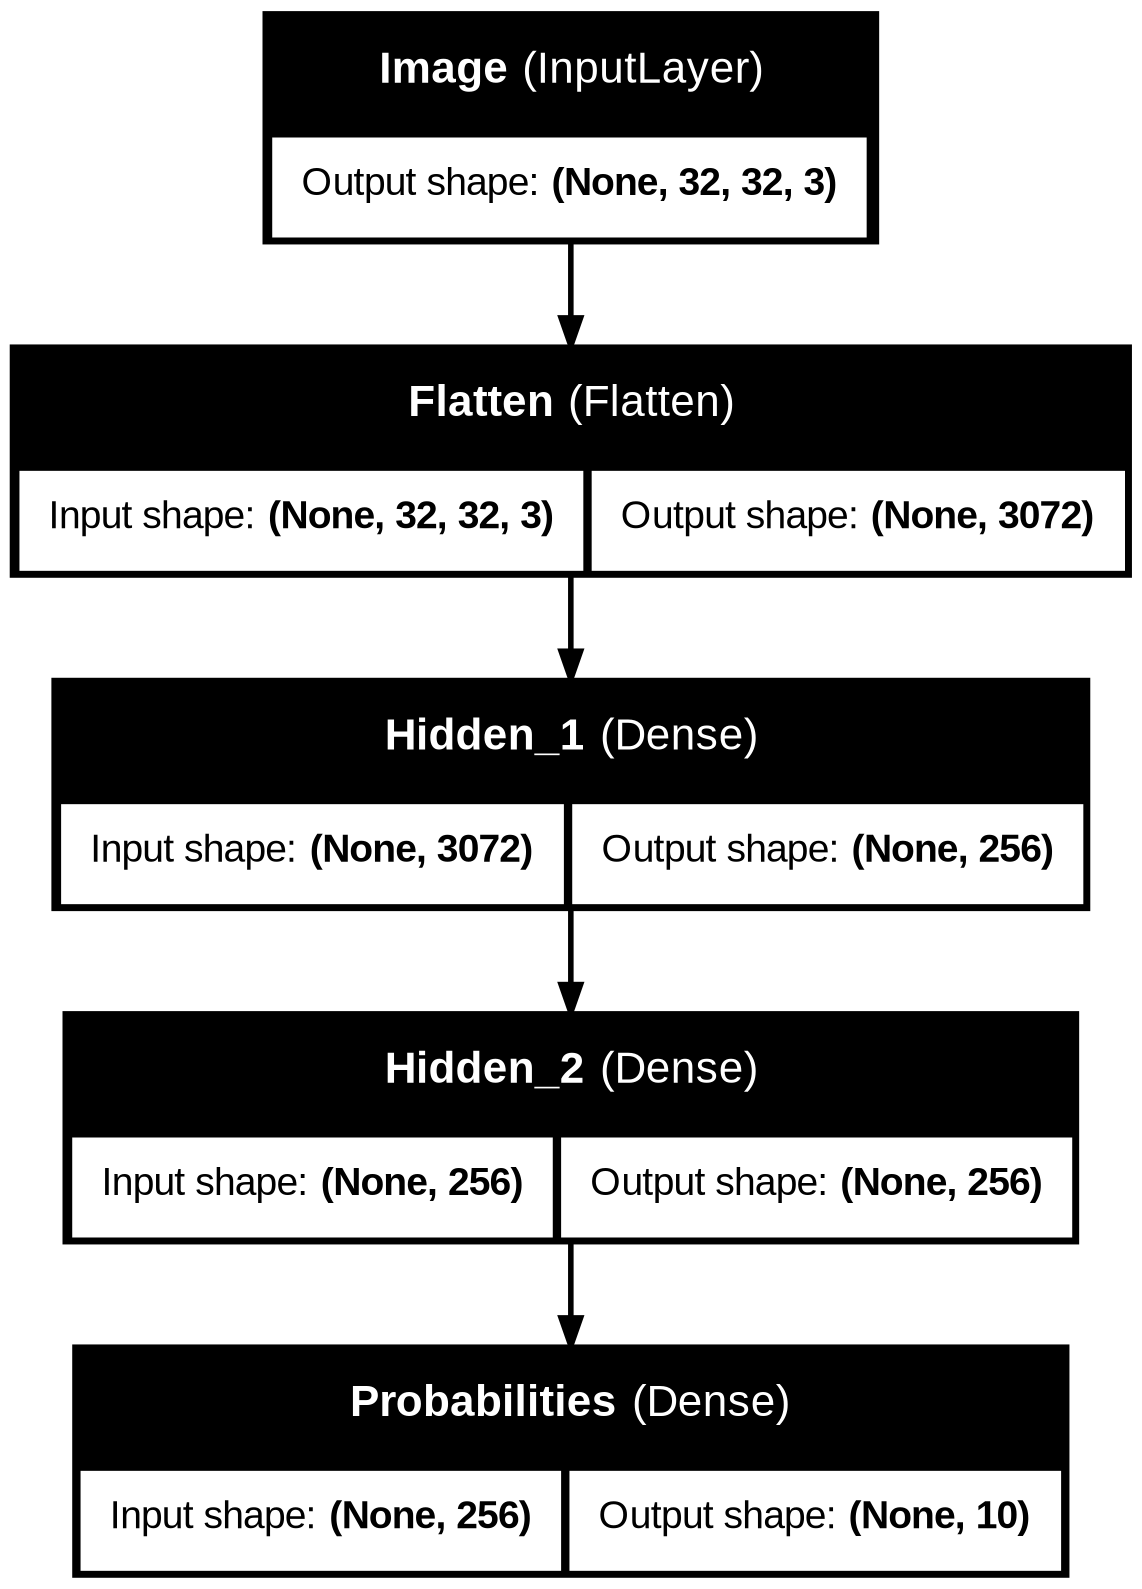

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import Image, display

# Requires pydot and Graphviz for plot_model().
def make_dense_classifier(image_shape, name):
    inputs = keras.Input(shape=image_shape, name="Image")
    x = layers.Flatten(name="Flatten")(inputs)
    x = layers.Dense(256, activation="relu", name="Hidden_1")(x)
    x = layers.Dense(256, activation="relu", name="Hidden_2")(x)
    outputs = layers.Dense(10, activation="softmax", name="Probabilities")(x)
    return keras.Model(inputs, outputs, name=name)

for shape, name, path in [
    ((28, 28), "MNIST_Grayscale", "demo_mnist_architecture.png"),
    ((32, 32, 3), "CIFAR10_RGB", "demo_cifar_architecture.png"),
]:
    model = make_dense_classifier(shape, name)
    model.summary()
    print(name, "trainable parameters:", model.count_params())
    keras.utils.plot_model(model, to_file=path,
                           show_shapes=True, show_layer_names=True)
    display(Image(filename=path))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
157/157 - 2s - 14ms/step - accuracy: 0.7489 - loss: 0.6998 - val_accuracy: 0.8105 - val_loss: 0.5150
Epoch 2/20
157/157 - 1s - 7ms/step - accuracy: 0.8310 - loss: 0.4659 - val_accuracy: 0.8360 - val_loss: 0.4665
Epoch 3/20
157/157 - 1s - 7ms/step - accuracy: 0.8528 - loss: 0.4066 - val_accuracy: 0.8410 - val_loss: 0.4745
Epoch 4/20
157/157 - 1s - 7ms/step - accuracy: 0.8639 - loss: 0.3673 - val_accuracy: 0.8490 - val_loss: 0.4406
Epoch 5/20
157/157 - 1s - 9ms/step - accuracy: 0.8743 - loss: 0.3387 - val_accuracy: 0.8610 - val_loss: 0.4115
Epoch 6/20
157/157 - 3s - 22ms/step - accuracy: 0.8846 - loss: 0.3105 - val_accuracy: 0.8595 - val_loss: 0.3965
Epoch 7/20
157/157 - 1s - 7ms/step - accuracy: 0.8931 - loss: 0.2838 - val_accuracy: 0.8675 - val_loss: 0.4029
Epoch 8/20
157/157 - 1s - 7ms/ste

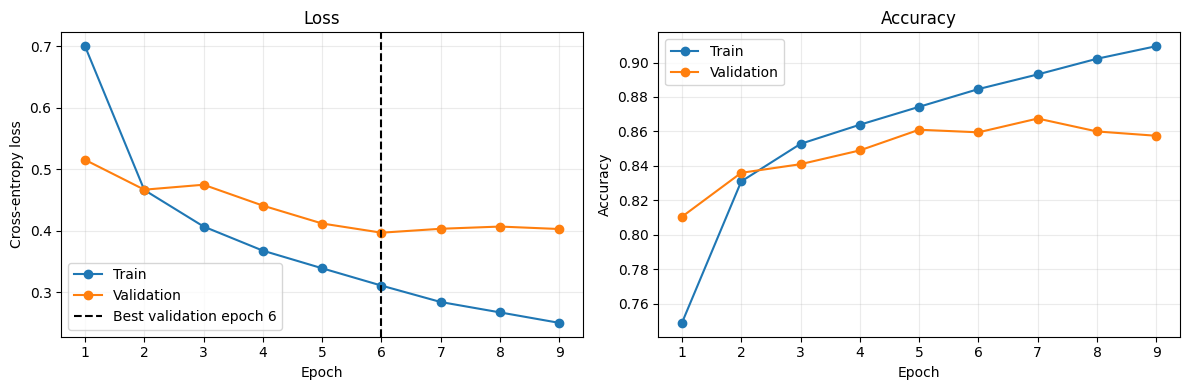

Completed epochs: 9
Best observed validation epoch: 6
Test result (not used for early stopping): [0.45292046666145325, 0.8414999842643738]


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
(x_full, y_full), (x_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

# Classroom-sized training/validation subsets, kept separate from the test set.
x_train = x_full[:10000].astype("float32") / 255.0
y_train = y_full[:10000]
x_val = x_full[10000:12000].astype("float32") / 255.0
y_val = y_full[10000:12000]
x_test = x_test_raw.astype("float32") / 255.0

inputs = keras.Input(shape=(28, 28))
x = layers.Flatten()(inputs)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(256, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
demo_model = keras.Model(inputs, outputs, name="Demo_Fashion_Classifier")
demo_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])

callback = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
demo_history = demo_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20, batch_size=64, callbacks=[callback], verbose=2
)

h = demo_history.history
epochs = np.arange(1, len(h["loss"]) + 1)
best_epoch = int(np.argmin(h["val_loss"])) + 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, h["loss"], marker="o", label="Train")
axes[0].plot(epochs, h["val_loss"], marker="o", label="Validation")
axes[0].axvline(best_epoch, linestyle="--", color="black",
                label=f"Best validation epoch {best_epoch}")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(epochs, h["accuracy"], marker="o", label="Train")
axes[1].plot(epochs, h["val_accuracy"], marker="o", label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Completed epochs:", len(epochs))
print("Best observed validation epoch:", best_epoch)
print("Test result (not used for early stopping):",
      demo_model.evaluate(x_test, y_test, verbose=0))

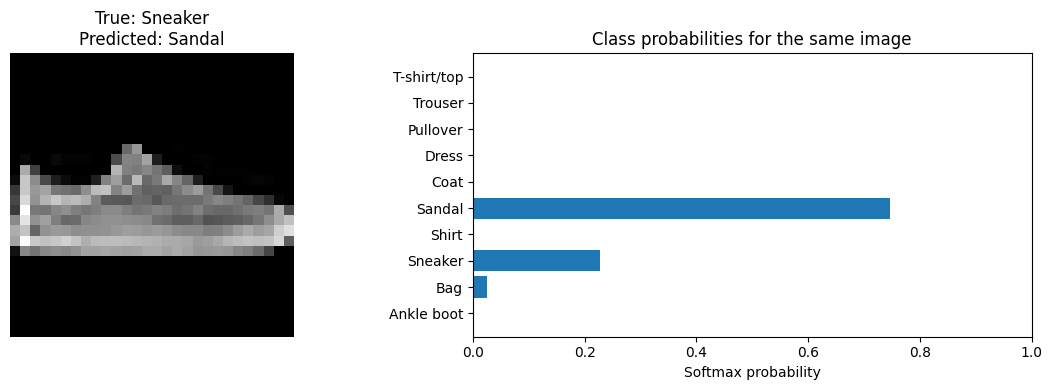

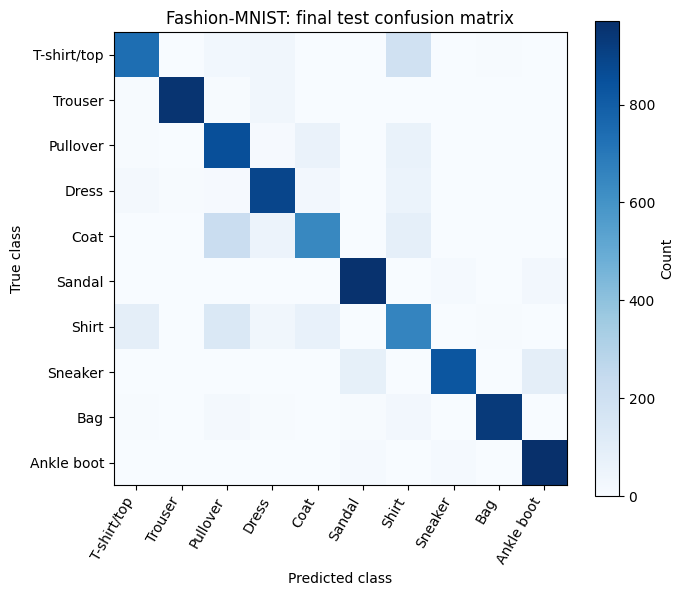

In [10]:
import numpy as np
import matplotlib.pyplot as plt

names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
         "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
probabilities = demo_model.predict(x_test, verbose=0)
predicted = np.argmax(probabilities, axis=1)
incorrect = np.flatnonzero(predicted != y_test)
chosen = int(incorrect[0]) if len(incorrect) else 0

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(x_test[chosen], cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"True: {names[int(y_test[chosen])]}\n"
                  f"Predicted: {names[int(predicted[chosen])]}")
axes[0].axis("off")
axes[1].barh(np.arange(10), probabilities[chosen])
axes[1].set_yticks(np.arange(10), names)
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 1), xlabel="Softmax probability",
            title="Class probabilities for the same image")
plt.tight_layout()
plt.show()

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test.astype(int), predicted.astype(int)), 1)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10), names, rotation=60, ha="right")
ax.set_yticks(range(10), names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Fashion-MNIST: final test confusion matrix")
fig.colorbar(im, ax=ax, label="Count")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sequential = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="Fashion_Sequential")

inputs = keras.Input(shape=(28, 28))
x = layers.Flatten()(inputs)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(256, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
functional = keras.Model(inputs, outputs, name="Fashion_Functional")

class FashionSubclass(keras.Model):
    def __init__(self):
        super().__init__(name="Fashion_Subclass")
        self.flatten_layer = layers.Flatten()
        self.hidden1 = layers.Dense(256, activation="relu")
        self.hidden2 = layers.Dense(256, activation="relu")
        self.output_layer = layers.Dense(10, activation="softmax")

    def call(self, inputs, training=False):
        x = self.flatten_layer(inputs)
        x = self.hidden1(x)
        x = self.hidden2(x)
        return self.output_layer(x)

subclassed = FashionSubclass()
_ = subclassed(tf.zeros((1, 28, 28)))  # Create subclassed weights.

for m in (sequential, functional, subclassed):
    print(m.name, "parameters:", m.count_params())

# Compare identical parameters rather than independently random initializations.
functional.set_weights(sequential.get_weights())
subclassed.set_weights(sequential.get_weights())
sample = tf.zeros((2, 28, 28), dtype=tf.float32)
p0 = sequential(sample, training=False).numpy()
p1 = functional(sample, training=False).numpy()
p2 = subclassed(sample, training=False).numpy()
print("Sequential and Functional agree:", np.allclose(p0, p1))
print("Sequential and subclassed agree:", np.allclose(p0, p2))

Fashion_Sequential parameters: 269322
Fashion_Functional parameters: 269322
Fashion_Subclass parameters: 269322
Sequential and Functional agree: True
Sequential and subclassed agree: True


In [12]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sequential = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="Fashion_Sequential")

inputs = keras.Input(shape=(28, 28))
x = layers.Flatten()(inputs)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(256, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
functional = keras.Model(inputs, outputs, name="Fashion_Functional")

class FashionSubclass(keras.Model):
    def __init__(self):
        super().__init__(name="Fashion_Subclass")
        self.flatten_layer = layers.Flatten()
        self.hidden1 = layers.Dense(256, activation="relu")
        self.hidden2 = layers.Dense(256, activation="relu")
        self.output_layer = layers.Dense(10, activation="softmax")

    def call(self, inputs, training=False):
        x = self.flatten_layer(inputs)
        x = self.hidden1(x)
        x = self.hidden2(x)
        return self.output_layer(x)

subclassed = FashionSubclass()
_ = subclassed(tf.zeros((1, 28, 28)))  # Create subclassed weights.

for m in (sequential, functional, subclassed):
    print(m.name, "parameters:", m.count_params())

# Compare identical parameters rather than independently random initializations.
functional.set_weights(sequential.get_weights())
subclassed.set_weights(sequential.get_weights())
sample = tf.zeros((2, 28, 28), dtype=tf.float32)
p0 = sequential(sample, training=False).numpy()
p1 = functional(sample, training=False).numpy()
p2 = subclassed(sample, training=False).numpy()
print("Sequential and Functional agree:", np.allclose(p0, p1))
print("Sequential and subclassed agree:", np.allclose(p0, p2))

Fashion_Sequential parameters: 269322
Fashion_Functional parameters: 269322
Fashion_Subclass parameters: 269322
Sequential and Functional agree: True
Sequential and subclassed agree: True
